# 00 — Chapman-Shaoxing Sample Waveforms (`[11, 13, 19, 92, 42]`)

Quick visual inspection of five individual 12-lead Chapman-Shaoxing recordings (`500 Hz`, `10 s`, `5,000` samples per lead) at dataset indices **`11`, `13`, `19`, `92`, and `42`**:

1. **Metadata & SNOMED-CT Summary** for the five selected records.
2. **Full 12-Lead Waveform Plots** (`6 × 2` grid, all `10 s`) for each sample.
3. **Cross-Sample Lineplots** comparing Lead II and Lead V2 (`0–5 s` zoom) side by side.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "chapman_shaoxing" / "quality" / "error_labels.csv").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate chapman_shaoxing/quality/error_labels.csv from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from chapman_shaoxing import ChapmanShaoxingDataset

CHAPMAN_DIR = REPO_ROOT / "chapman_shaoxing"
DATA_DIR = CHAPMAN_DIR / "data"
QUALITY_DIR = CHAPMAN_DIR / "quality"
LEADS = ChapmanShaoxingDataset.LEADS

df = pd.read_csv(QUALITY_DIR / "error_labels.csv", index_col="record_id")
df["snomed_codes"] = df["snomed_codes"].fillna("")
df["label_names"] = df["label_names"].fillna("")
df["error_tags"] = df["error_tags"].fillna("")
df["sex"] = df["sex"].fillna("")

SAMPLE_INDICES = [11, 13, 19, 92, 42]
sub = df.iloc[SAMPLE_INDICES].copy()
sub.insert(0, "sample_idx", SAMPLE_INDICES)

signals = {}
meta_rows = []
for rec_id, row in sub.iterrows():
    idx = int(row["sample_idx"])
    sig, _ = wfdb.rdsamp(str(DATA_DIR / row["record_path"]))
    signals[idx] = np.nan_to_num(sig).astype(np.float32)  # (5000, 12)
    meta_rows.append({
        "sample_idx": idx,
        "record_id": rec_id,
        "age": row["age"],
        "sex": row["sex"],
        "duration_s": row["duration_s"],
        "label_names": row["label_names"],
        "severity_tier": row["severity_tier"],
    })

meta_df = pd.DataFrame(meta_rows).set_index("sample_idx")
display(meta_df)

,record_id,age,sex,duration_s,label_names,severity_tier
sample_idx,,,,,,
11,JS00013,54.0,Male,10.0,SB|1AVB,0_clean
13,JS00015,54.0,Female,10.0,SB,0_clean
19,JS00021,46.0,Female,10.0,SR,0_clean
92,JS00096,81.0,Male,10.0,ST|1AVB|IDC|LBBB|STTC,0_clean
42,JS00046,80.0,Female,10.0,AFIB|STTC|VPB,0_clean


## 1. Full 12-Lead Waveform Plots (`10 s @ 500 Hz`)

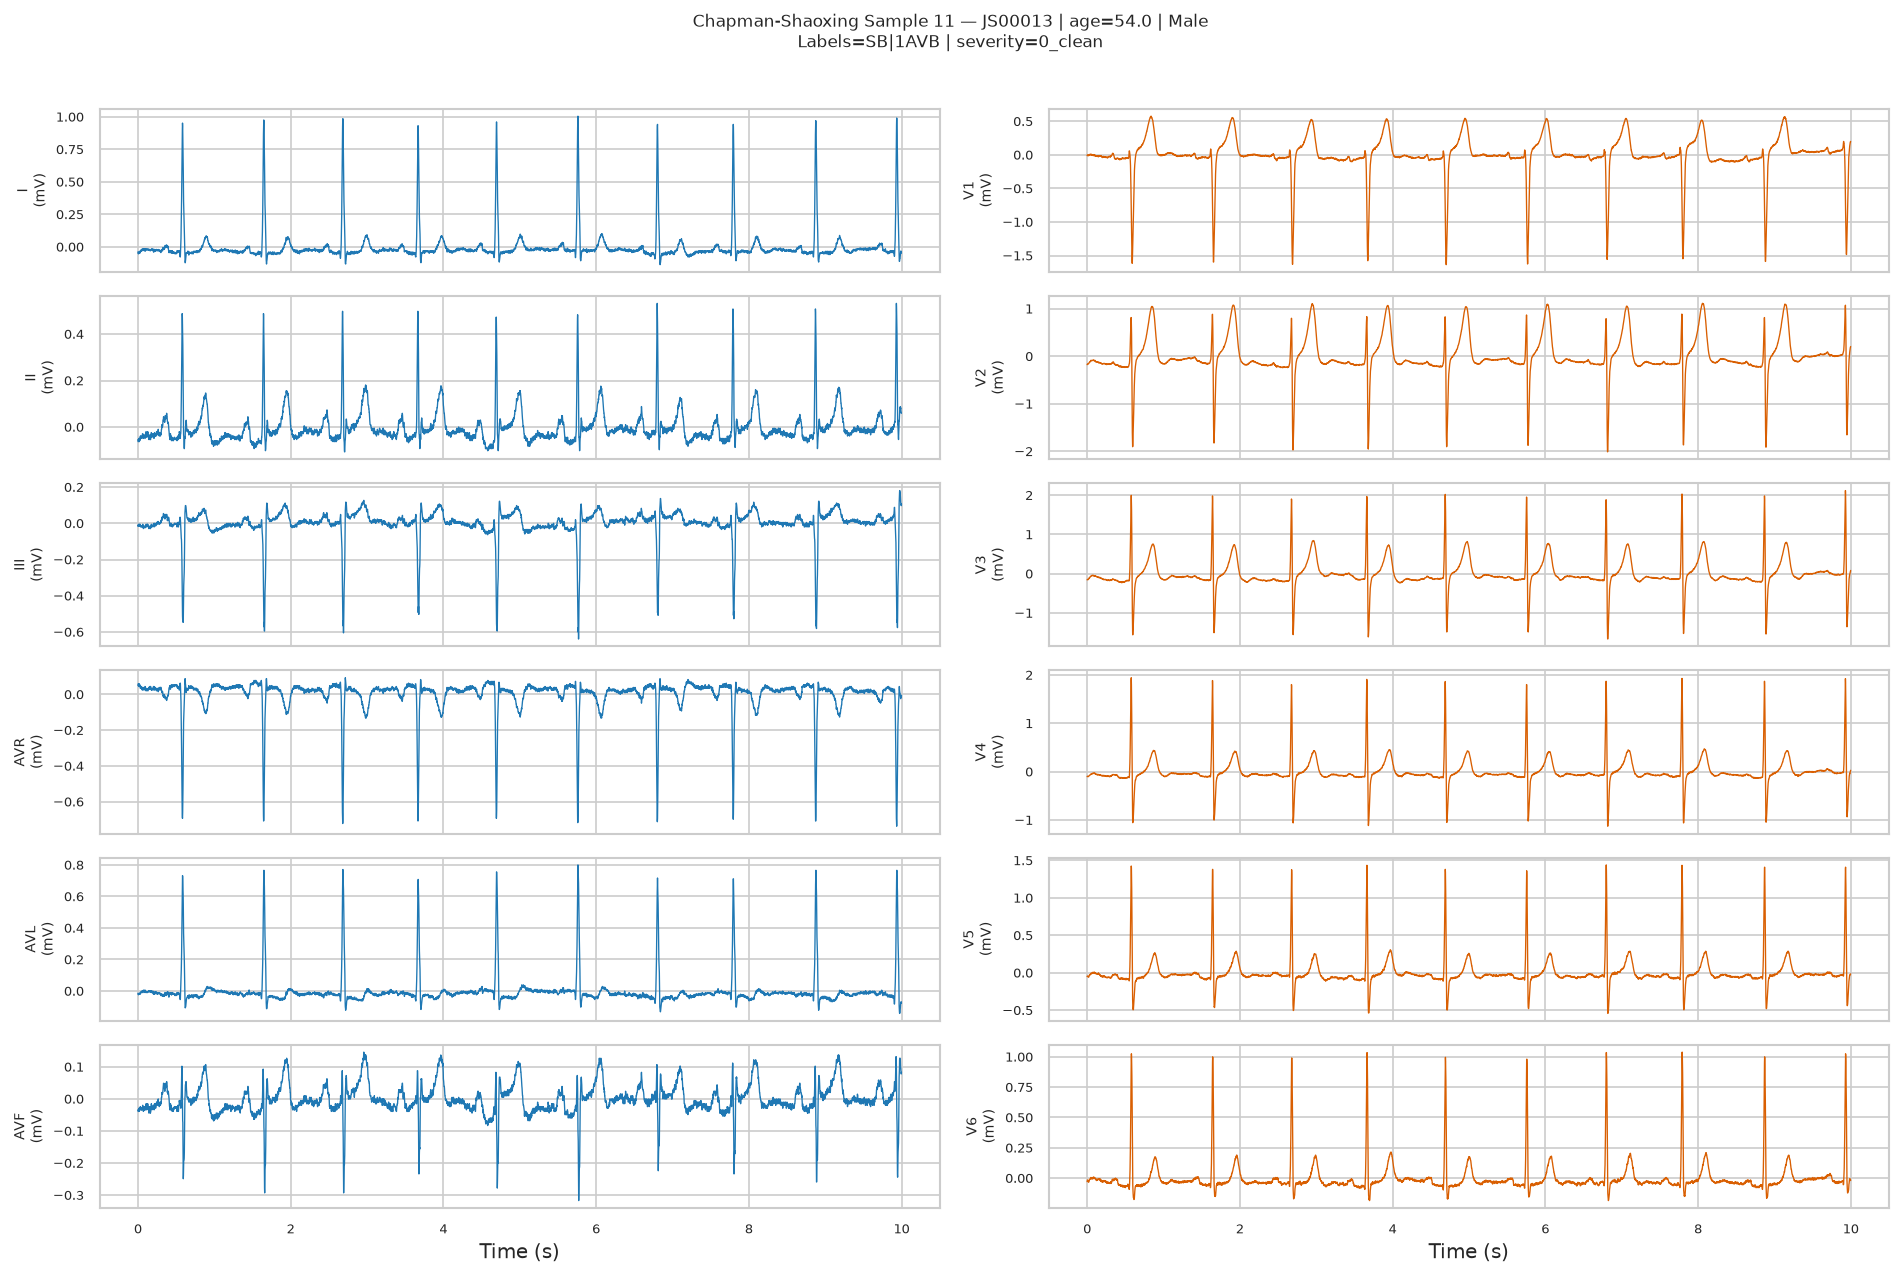

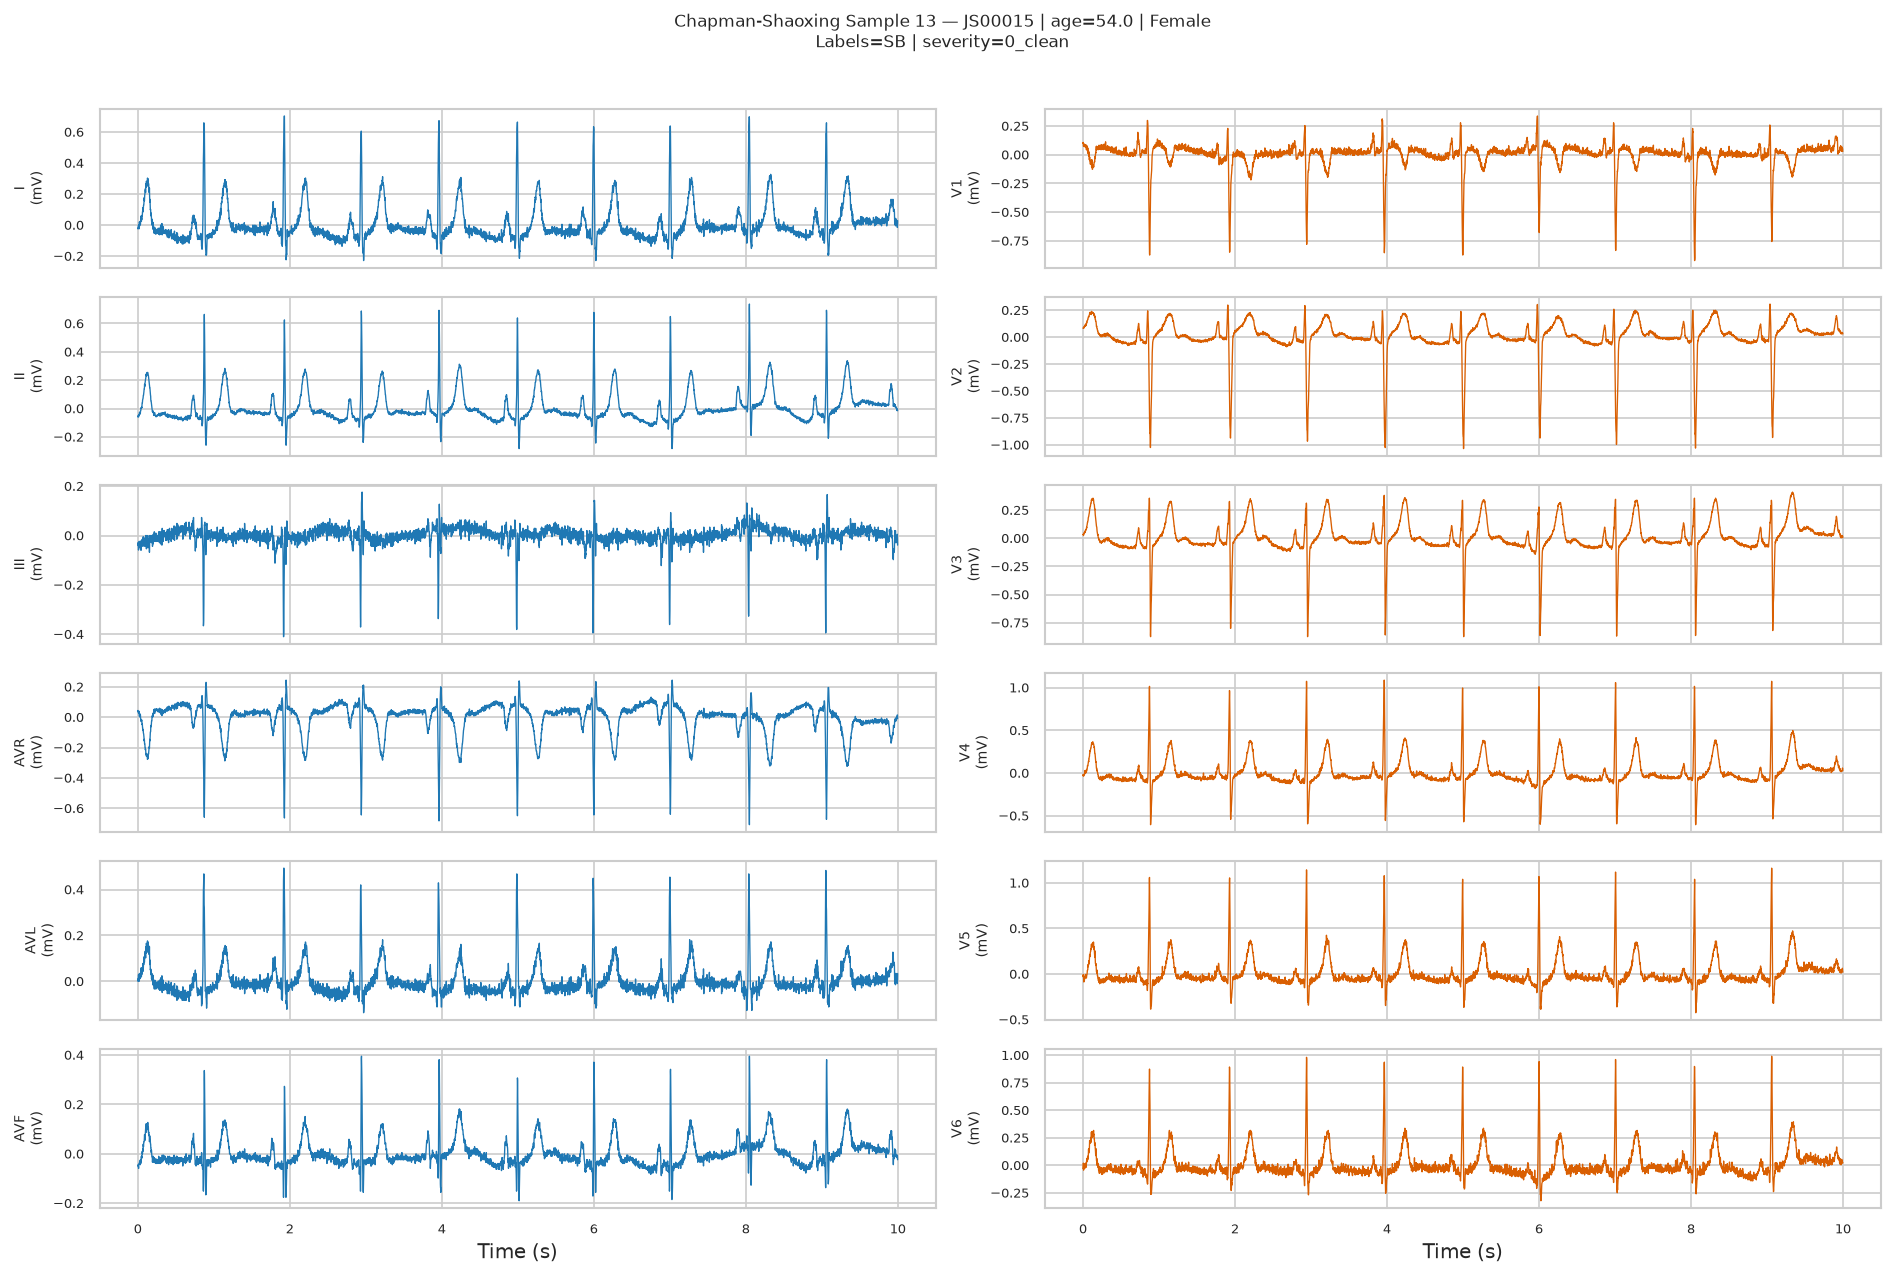

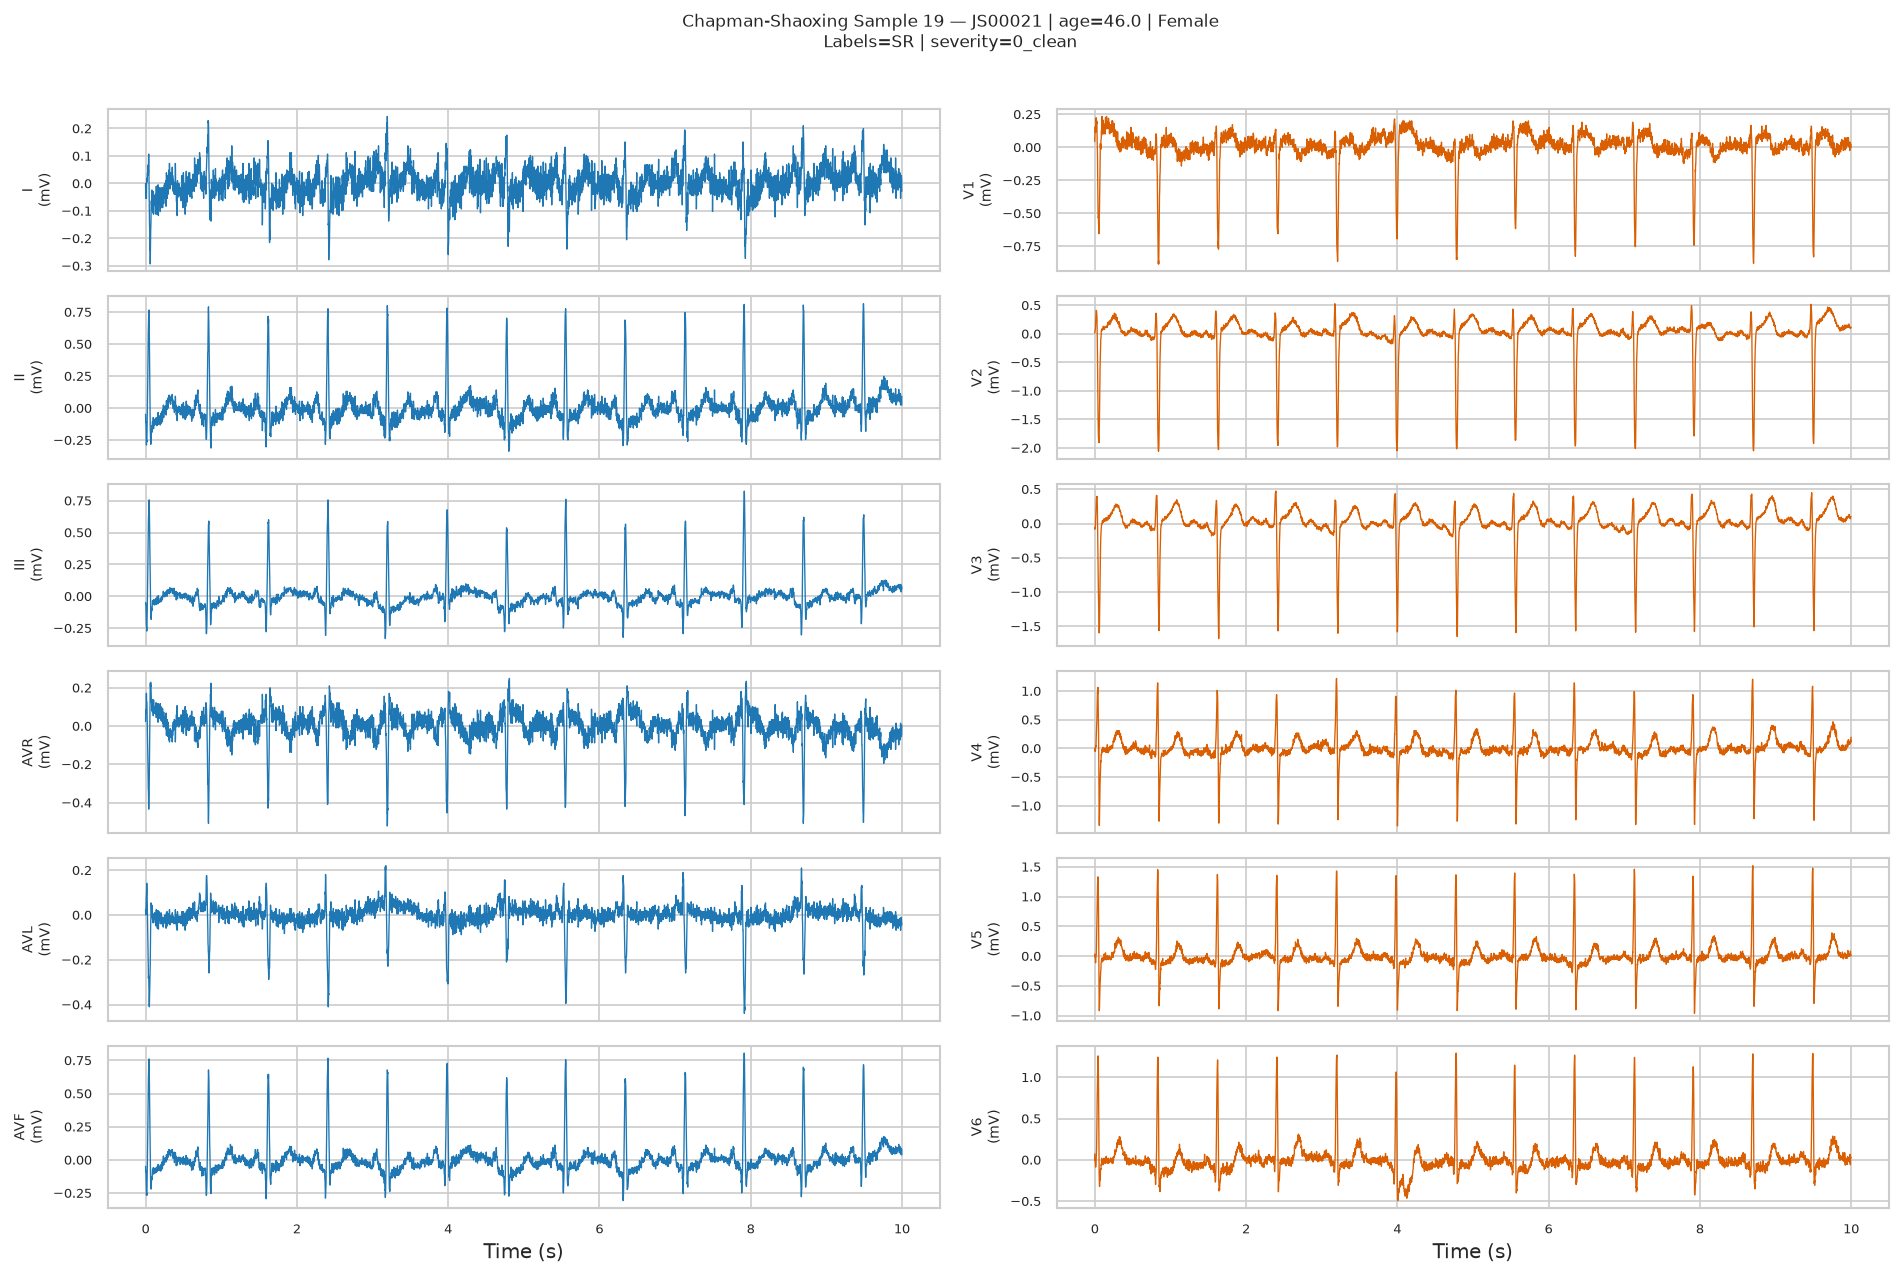

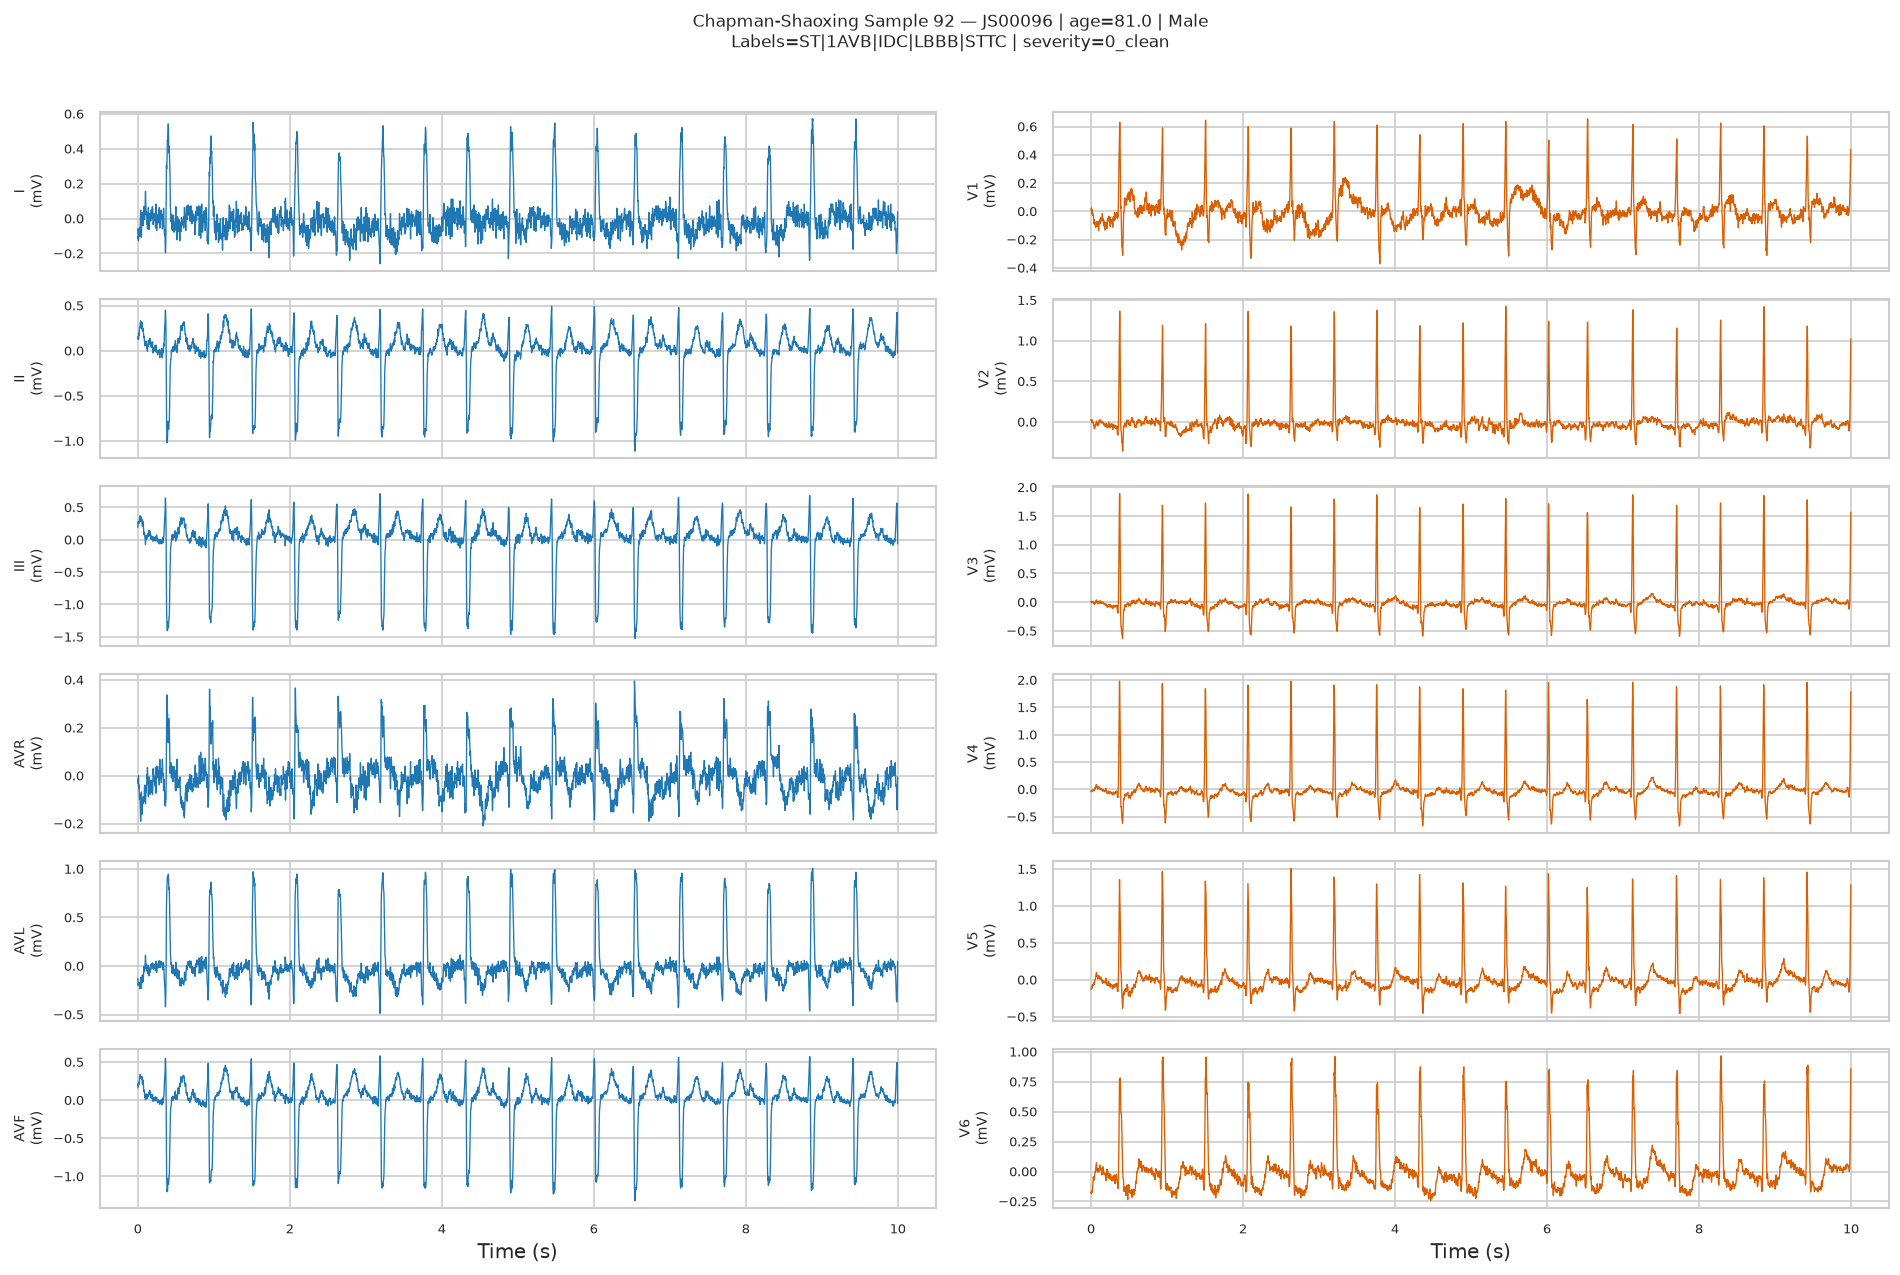

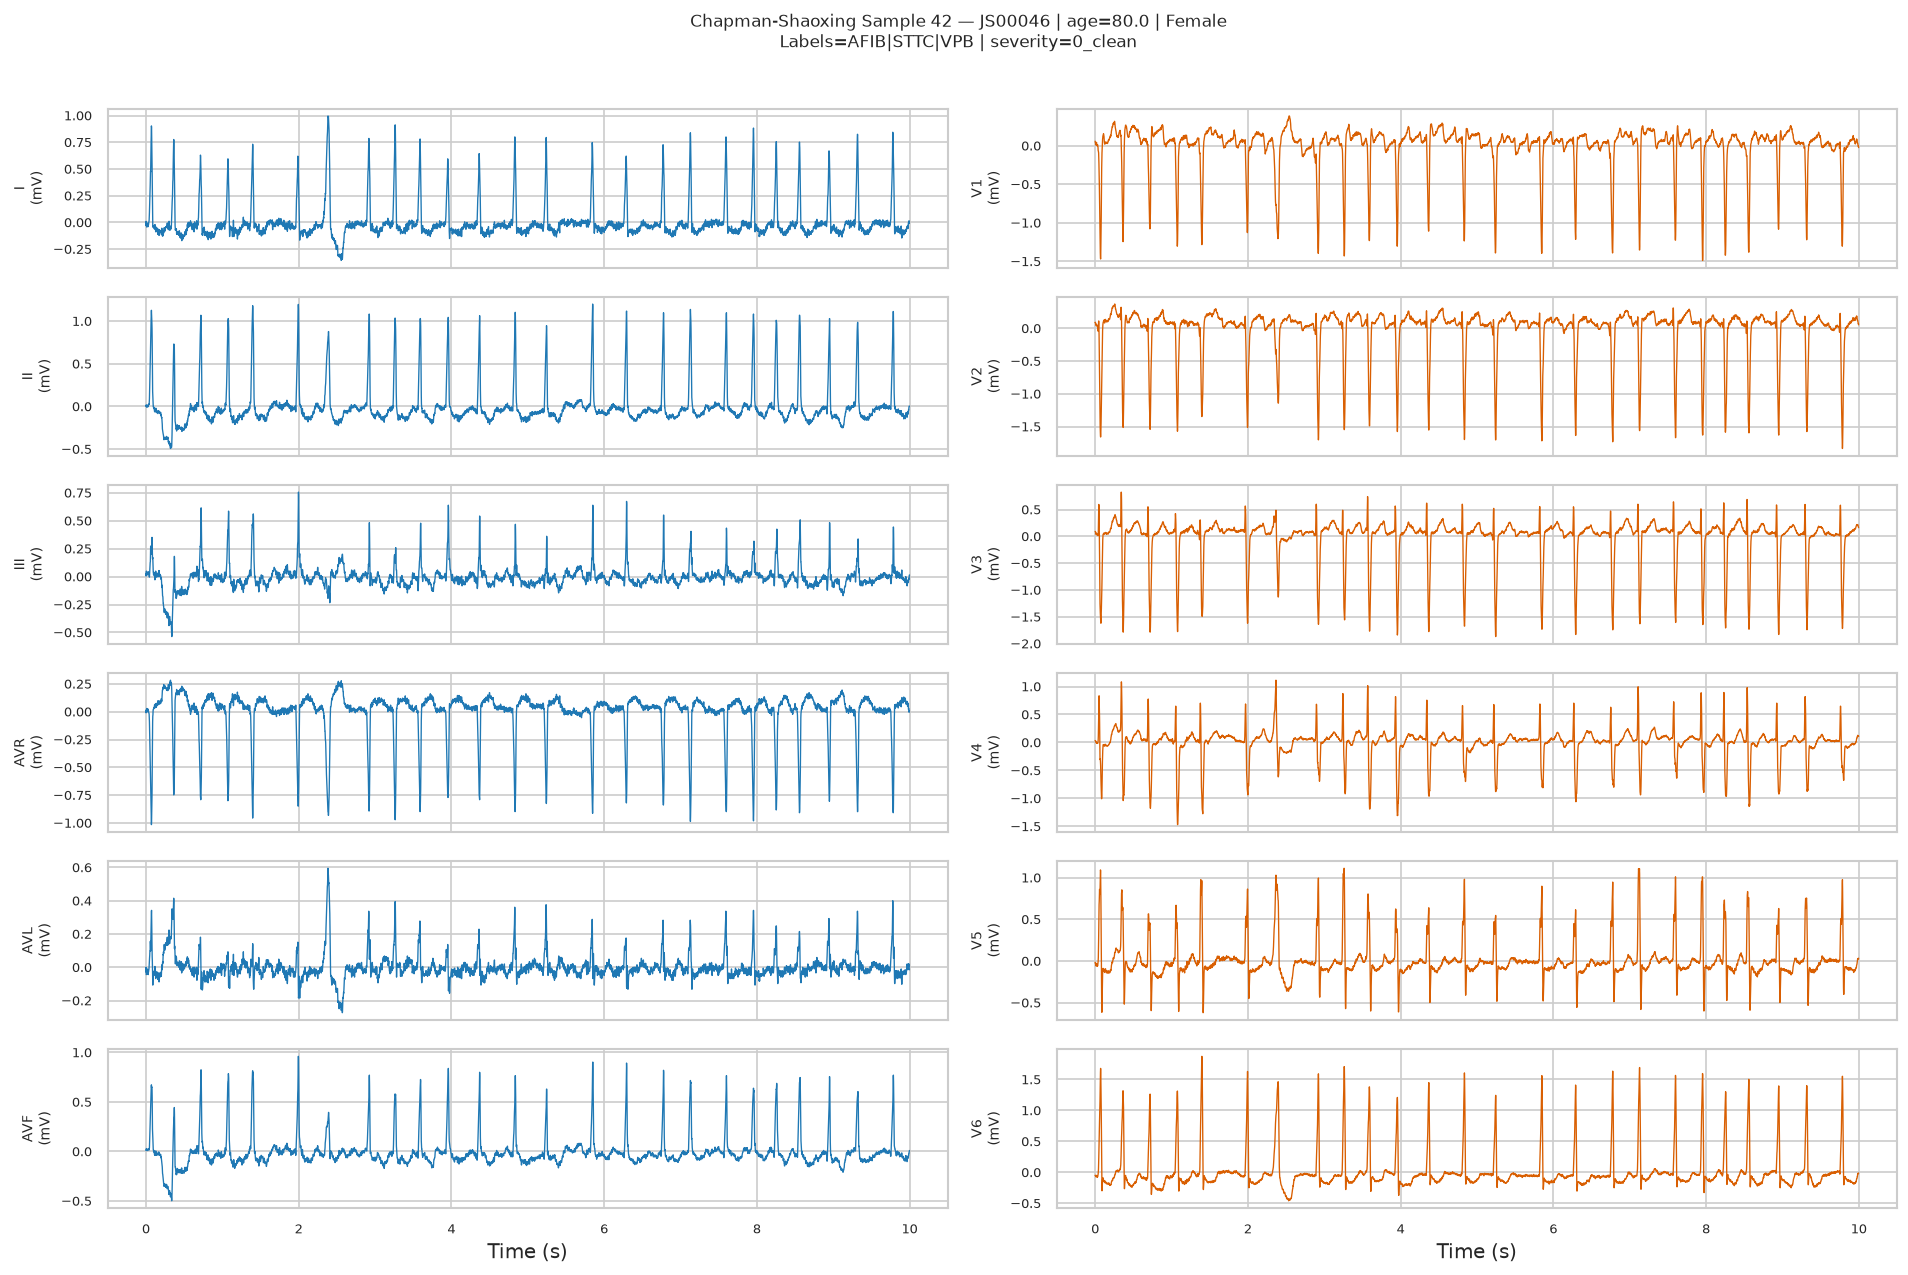

In [2]:
for idx in SAMPLE_INDICES:
    sig = signals[idx]
    row = meta_df.loc[idx]
    t_full = np.arange(sig.shape[0]) / 500.0
    fig, axes = plt.subplots(6, 2, figsize=(16, 10.5), sharex=True)
    for j, lname in enumerate(LEADS):
        ax = axes[j % 6, j // 6]
        ax.plot(t_full, sig[:, j], color="#1f78b4" if j < 6 else "#d95f02", lw=0.8)
        ax.set_ylabel(f"{lname}\n(mV)", fontsize=8.5)
        ax.tick_params(labelsize=7.5)
    axes[5, 0].set_xlabel("Time (s)")
    axes[5, 1].set_xlabel("Time (s)")
    fig.suptitle(
        f"Chapman-Shaoxing Sample {idx} — {row['record_id']} | age={row['age']} | {row['sex']}\n"
        f"Labels={row['label_names']} | severity={row['severity_tier']}",
        y=1.01, fontsize=10.2,
    )
    plt.tight_layout()
    plt.show()

## 2. Side-by-Side Lineplot Comparison (`0–5 s` Zoom: Lead II & Lead V2)

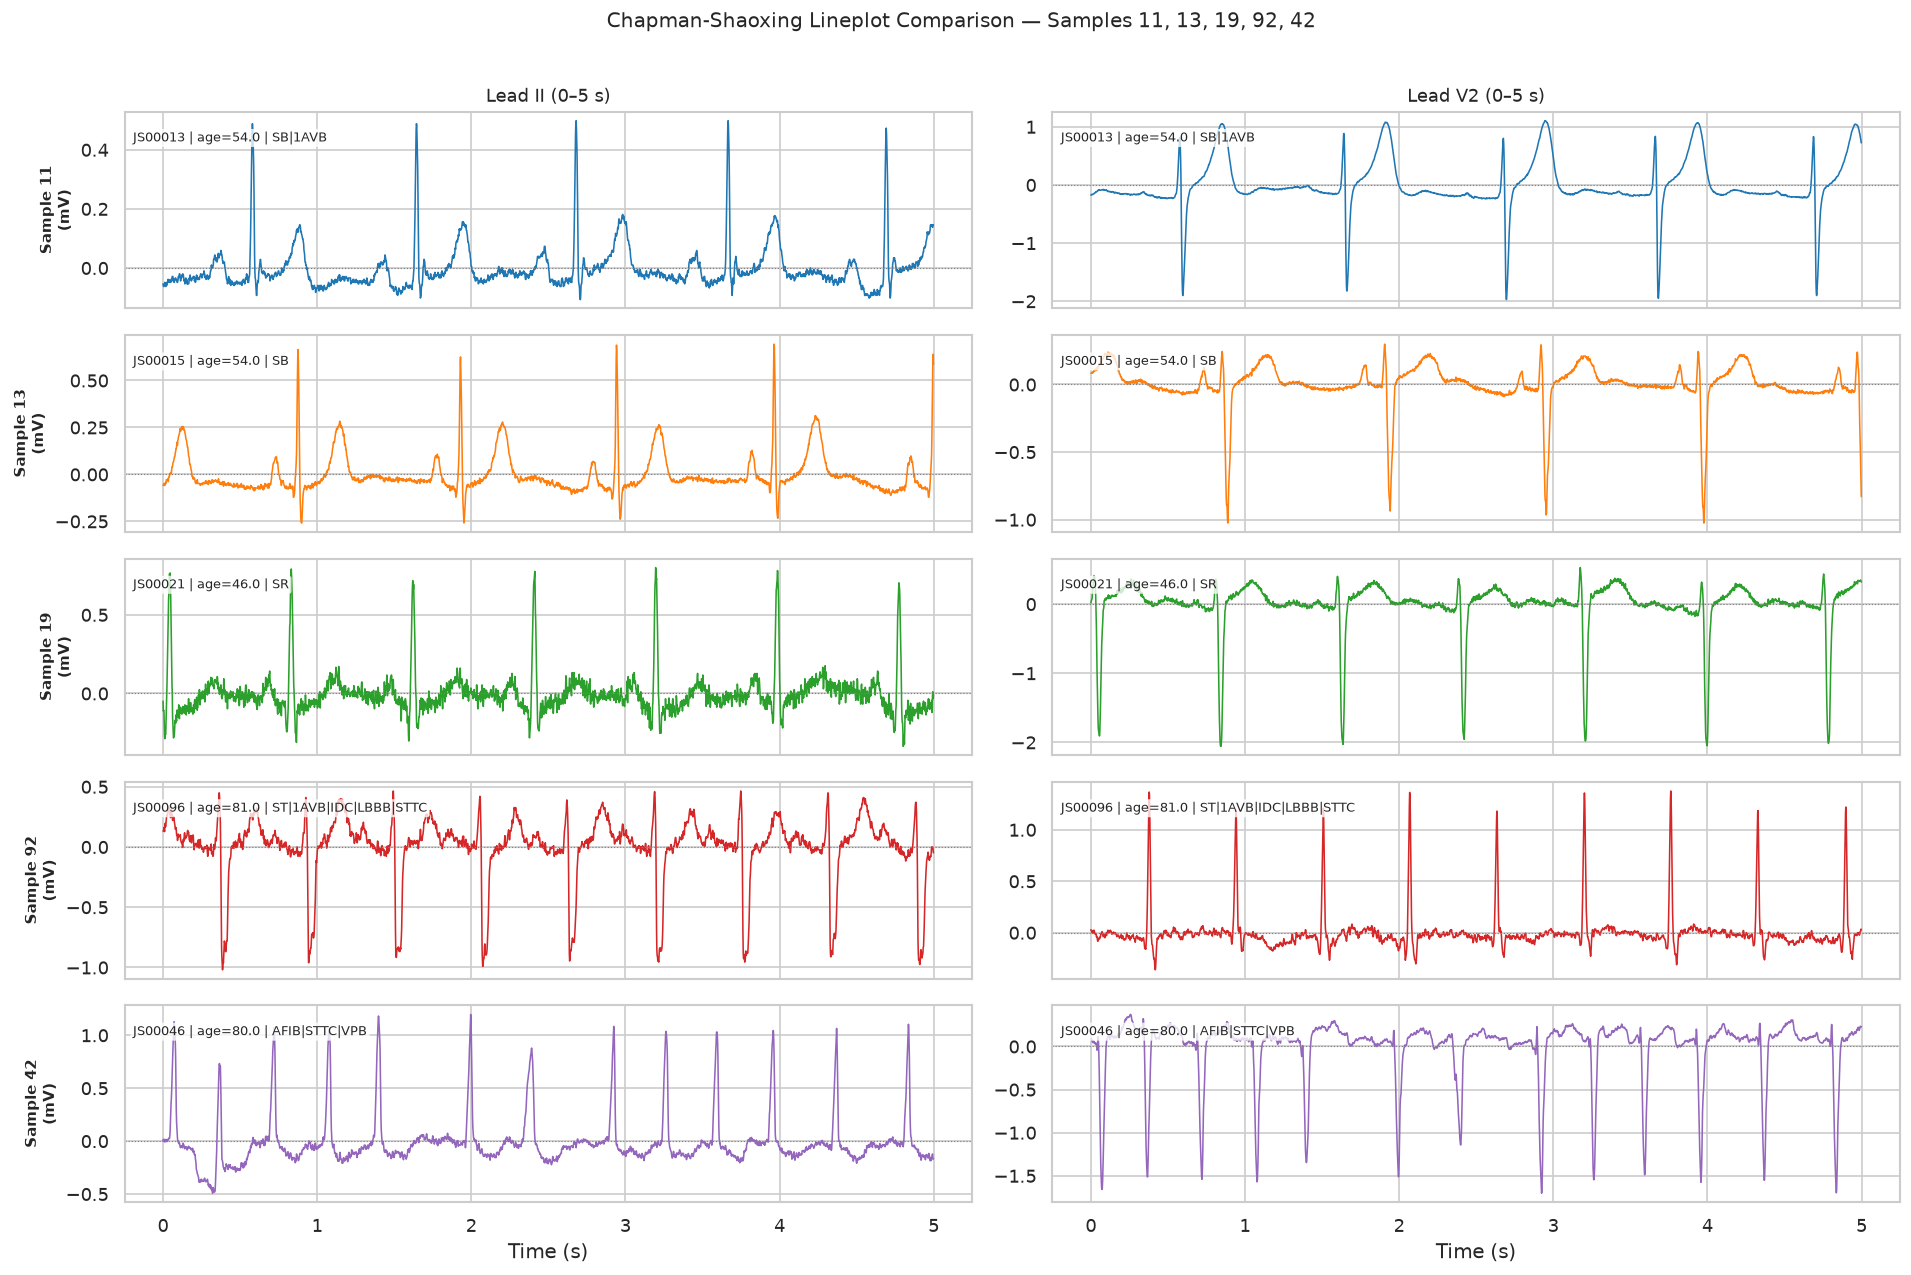

In [3]:
T_ZOOM = 2500  # 5.0 seconds @ 500 Hz
colors = sns.color_palette("tab10", n_colors=len(SAMPLE_INDICES))

fig, axes = plt.subplots(len(SAMPLE_INDICES), 2, figsize=(16, 10.5), sharex=True)
for r_i, (idx, col) in enumerate(zip(SAMPLE_INDICES, colors)):
    sig = signals[idx]
    row = meta_df.loc[idx]
    n_pts = min(T_ZOOM, sig.shape[0])
    t_zoom = np.arange(n_pts) / 500.0
    for c_i, (l_idx, lname) in enumerate([(1, "II"), (7, "V2")]):
        ax = axes[r_i, c_i]
        ax.plot(t_zoom, sig[:n_pts, l_idx], color=col, lw=0.95)
        ax.axhline(0, color="gray", ls=":", lw=0.7)
        if c_i == 0:
            ax.set_ylabel(f"Sample {idx}\n(mV)", fontsize=9, fontweight="bold")
        if r_i == 0:
            ax.set_title(f"Lead {lname} (0–5 s)", fontsize=10.5)
        ax.text(
            0.01, 0.90,
            f"{row['record_id']} | age={row['age']} | {row['label_names']}",
            transform=ax.transAxes, fontsize=7.5, va="top",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.78, edgecolor="none"),
        )

axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Time (s)")
fig.suptitle("Chapman-Shaoxing Lineplot Comparison — Samples 11, 13, 19, 92, 42", y=1.01, fontsize=12)
plt.tight_layout()
plt.show()